<a href="https://colab.research.google.com/github/draganmihaela/ML-Seminar-DraganMihaela/blob/main/LP_8_1_KNN_complet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Seminar 5 - Algoritmul K-Nearest Neighbors (KNN)

Obiective:
După finalizarea acestui laborator, veți putea:
- să utilizați scikit-learn pentru a implementa modelul KNN;
- să creați un model, să îl antrenați, să îl testați și să îl utilizați;
- să alegeți numărul de vecini **k** prin validare încrucișată;
- să înțelegeți de ce **standardizarea datelor** este esențială pentru KNN și să o aplicați corect (fără scurgere de informație din setul de test).

In [1]:
!pip install scikit-learn


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Biblioteci de bază
import pandas as pd
import numpy as np
import itertools

In [4]:
# Biblioteci de Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

In [5]:
# Biblioteci pentru metrici
from sklearn import metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix)

In [6]:
# Biblioteci de vizualizare
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

import warnings
warnings.filterwarnings('ignore')

In [7]:
# ruleaza aceasta celula fara a o modifica atunci cand lucrezi in google colab pentru a importa (mapa) Google Drive.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Breast Cancer Wisconsin (Diagnostic) Data Set - Prezicerea dacă tumora este benignă sau malignă**

Caracteristicile (features) sunt calculate dintr-o imagine digitalizată a unei aspirații cu ac fin (FNA) dintr-o masă mamară. Aceste caracteristici descriu proprietățile nucleelor celulare prezente în imagine.
Spațiul tridimensional utilizat este cel descris în:
[K. P. Bennett și O. L. Mangasarian: „Robust Linear Programming Discrimination of Two Linearly Inseparable Sets”, Optimization Methods and Software 1, 1992, pp. 23–34].”

Baza de date este preluată de pe Kaggle: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data/data

In [9]:
#Citirea datelor intr-un dataframe

df=pd.read_csv('/content/drive/MyDrive/Machine Learning 2026/data_Breast Cancer.csv')


In [10]:
#Afisarea primelor 10 linii din tabel

df.head(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [11]:
df.shape

(569, 32)

In [12]:
#tipul datelor
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [13]:
#verificarea valorilor lipsă
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


# Preprocesarea datelor:



In [14]:
#eliminarea coloanelor ce nu sunt necesare
df = df.drop('id', axis=1)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


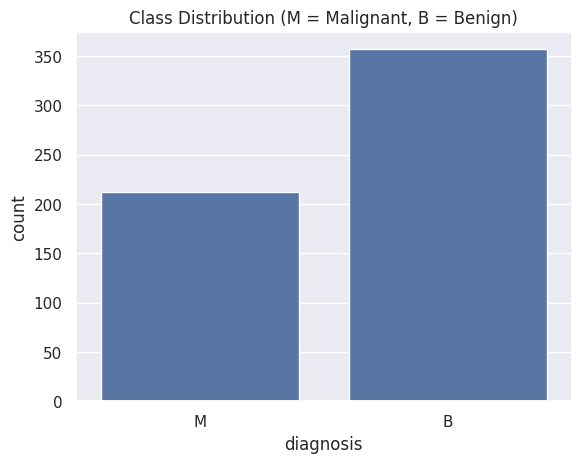

,count
diagnosis,
B,357
M,212


In [15]:
#verificarea distributiei pe cele două clase
sns.countplot(x=df['diagnosis'])
plt.title("Class Distribution (M = Malignant, B = Benign)")
plt.show()

df['diagnosis'].value_counts()

In [16]:
#asignarea valorilor binare
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Crearea seturilor de date de antrenare și de testare

In [17]:
# Crearea matricilor pentru sklearn:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']          # Series (1D), nu DataFrame: scikit-learn așteaptă un vector

In [18]:
# Împărțirea setului de date în două: date de antrenare (70%) și date de test (30%).
# stratify=y păstrează aceeași proporție de tumori maligne în ambele seturi.
random_seed = 50

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=random_seed, stratify=y)
print('Train:', X_train.shape, '  Test:', X_test.shape)
print('Proporția tumorilor maligne - train:', round(y_train.mean(), 3), '  test:', round(y_test.mean(), 3))

Train: (398, 30)   Test: (171, 30)
Proporția tumorilor maligne - train: 0.372   test: 0.374


# Algoritmul K-Nearest Neighbors (KNN)

**KNeighborsClassifier**

(n_neighbors=5, *,

 weights='uniform',

 algorithm='auto',

 leaf_size=30,

 p=2,

 metric='minkowski',

 metric_params=None,

 n_jobs=None)

Distanța Minkowski de ordin *p* între două observații **x** și **z** este:

$$d(\mathbf{x}, \mathbf{z}) = \left(\sum_{j=1}^{m} |x_j - z_j|^p\right)^{1/p}$$

- pentru **p=2** se obține distanța **euclidiană**;
- pentru **p=1** se obține distanța **Manhattan** (city-block).

Ambele sunt cazuri particulare ale distanței Minkowski.

Alți parametri:
- `weights='uniform'`: toți cei k vecini votează la fel; `weights='distance'`: vecinii mai apropiați au o pondere mai mare;
- `algorithm` și `leaf_size` influențează doar **viteza** căutării vecinilor, nu rezultatul.

# Varianta 1: KNN pe datele nestandardizate

**Implementarea algoritmului KNN (k-Nearest Neighbors)**

In [19]:
# Inițializați clasificatorul KNN cu un anumit număr de vecini (în exemplul acesta, k=3)
knn_classifier = KNeighborsClassifier(n_neighbors=3)

# Antrenați modelul pe datele de antrenare
knn_classifier.fit(X_train, y_train)

# Realizați previziuni pe datele de test
Y_pred_KNN = knn_classifier.predict(X_test)

# Calculați acuratețea modelului
accuracy_KNN = accuracy_score(y_test, Y_pred_KNN)
print(f'Acuratețea modelului (k=3, date nestandardizate): {accuracy_KNN:.4f}')

Acuratețea modelului (k=3, date nestandardizate): 0.9298


**Alegerea celei mai bune valori a lui k prin validare încrucișată**

În codul următor selectăm un interval de valori pentru **k** și calculăm, pentru fiecare, acuratețea medie în **validarea încrucișată** (*cross-validation*) cu `cross_val_score` din scikit-learn.

Datele **de antrenare** sunt împărțite în **5 părți** (folds): modelul este antrenat de 5 ori pe 4 părți și evaluat pe partea rămasă. Se calculează apoi acuratețea medie pentru a găsi cel mai bun k.

**Important:** validarea încrucișată se face doar pe `X_train`. Setul de test nu trebuie folosit la alegerea lui k, altfel evaluarea finală devine prea optimistă.

In [20]:
k_values = list(range(1, 30))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)

scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, p=2, metric='minkowski')
    score = cross_val_score(knn, X_train, y_train, cv=cv, scoring='accuracy')
    scores.append(np.mean(score))

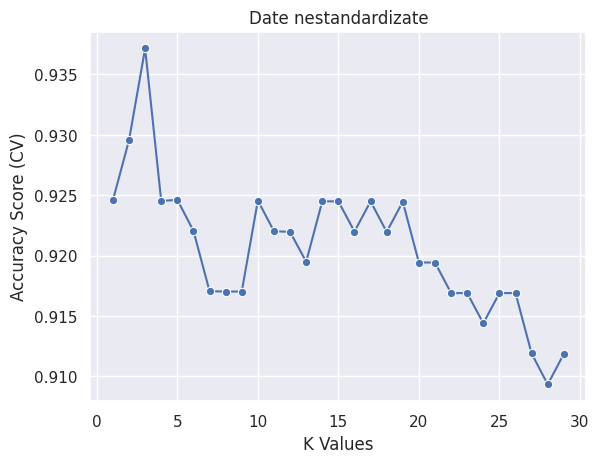

In [21]:
# Reprezentarea grafică a rezultatelor
sns.lineplot(x=k_values, y=scores, marker='o')
plt.xlabel("K Values")
plt.ylabel("Accuracy Score (CV)")
plt.title("Date nestandardizate")
plt.show()

In [22]:
# Determinarea celei mai bune valori k
best_k = k_values[int(np.argmax(scores))]
print('Cel mai bun k (date nestandardizate):', best_k, '  acuratețe CV:', round(max(scores), 4))

Cel mai bun k (date nestandardizate): 3   acuratețe CV: 0.9372


**Alte măsuri de evaluare**

Accuracy_KNN:  0.9298
Precision_KNN: 0.9062
Recall_KNN:    0.9062


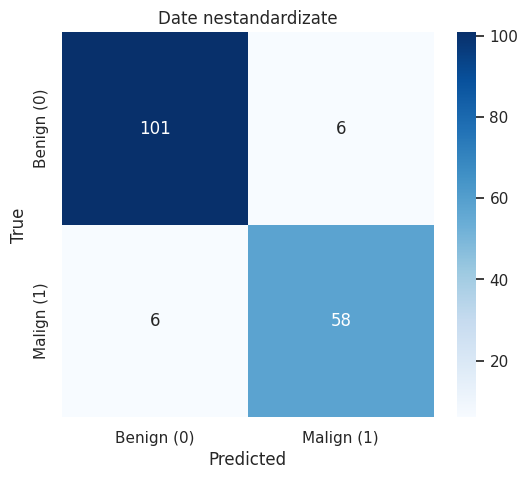

              precision    recall  f1-score   support

           0       0.94      0.94      0.94       107
           1       0.91      0.91      0.91        64

    accuracy                           0.93       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.93      0.93      0.93       171



In [23]:
# Antrenarea modelului folosind cea mai bună valoare k
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
y_prob = knn.predict_proba(X_test)[:, 1]

print("Accuracy_KNN: ", round(accuracy_score(y_test, y_pred), 4))
print("Precision_KNN:", round(precision_score(y_test, y_pred), 4))
print("Recall_KNN:   ", round(recall_score(y_test, y_pred), 4))

confusion_mat = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign (0)', 'Malign (1)'], yticklabels=['Benign (0)', 'Malign (1)'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Date nestandardizate')
plt.show()

print(classification_report(y_test, y_pred))

**Observație:** în problemele medicale, **recall-ul pentru clasa 1 (malign)** este de obicei mai important decât precizia: o tumoră malignă ratată (fals negativ) este mult mai gravă decât o alarmă falsă.

# Varianta 2: KNN pe datele standardizate

**De ce trebuie standardizate datele pentru KNN?**

KNN clasifică o observație după distanța față de vecinii ei. Dacă variabilele sunt măsurate pe scale foarte diferite, distanța este dominată aproape complet de variabilele cu valori mari. În setul nostru, `area_mean` și `area_worst` iau valori de ordinul sutelor sau miilor, în timp ce `smoothness_mean` sau `fractal_dimension_mean` iau valori de ordinul sutimilor. Fără standardizare, modelul ignoră practic aceste variabile.

Standardizarea transformă fiecare variabilă astfel încât să aibă media 0 și abaterea standard 1:

$$z = \frac{x - \bar{x}}{s}$$

In [24]:
# Scalele foarte diferite ale variabilelor
X_train[['area_worst', 'area_mean', 'perimeter_mean', 'radius_mean',
         'smoothness_mean', 'fractal_dimension_mean']].describe().round(3)

,area_worst,area_mean,perimeter_mean,radius_mean,smoothness_mean,fractal_dimension_mean
count,398.000,398.000,398.000,398.000,398.000,398.000
mean,862.951,640.876,91.175,14.013,0.096,0.063
std,530.244,323.549,22.838,3.317,0.014,0.007
min,185.200,143.500,43.790,6.981,0.053,0.050
25%,518.700,421.100,75.502,11.740,0.087,0.058
50%,685.500,541.700,85.815,13.275,0.096,0.062
75%,1031.750,792.025,104.250,15.960,0.105,0.066
max,3432.000,2499.000,188.500,28.110,0.140,0.093


In [25]:
# Cât din pătratul distanței euclidiene dintre două observații vine din fiecare variabilă?
# (medie pe 2000 de perechi de observații din setul de antrenare)
rng = np.random.default_rng(random_seed)
i, j = rng.integers(0, len(X_train), (2, 2000))
dif2 = (X_train.values[i] - X_train.values[j]) ** 2
contrib = pd.Series(dif2.mean(axis=0) / dif2.mean(axis=0).sum(), index=X_train.columns)
print('Ponderea fiecărei variabile în distanța euclidiană (date nestandardizate):')
contrib.sort_values(ascending=False).head(5).round(4)

Ponderea fiecărei variabile în distanța euclidiană (date nestandardizate):


,0
area_worst,0.7277
area_mean,0.2641
area_se,0.0041
perimeter_worst,0.0026
perimeter_mean,0.0013


**Interpretare:** pe datele nestandardizate, doar două-trei variabile (cele de arie) contribuie la aproape toată distanța; celelalte ~27 de variabile practic nu contează.

**Cum standardizăm corect?**
- media și abaterea standard se estimează **doar pe setul de antrenare** (`fit`) și se aplică apoi pe setul de test (`transform`);
- în validarea încrucișată, standardizarea trebuie refăcută **în interiorul fiecărui fold**. Cel mai simplu se face cu un `Pipeline`: scalerul și KNN devin un singur model, iar `cross_val_score` sau `GridSearchCV` reestimează scalerul doar pe partea de antrenare a fiecărui fold.

Dacă am standardiza tot setul de date înainte de împărțire, media și abaterea standard ar include și observațiile de test (*data leakage*).

In [26]:
# Standardizarea: scalerul se estimează DOAR pe datele de antrenare
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

pd.DataFrame(X_train_sc, columns=X_train.columns).describe().round(2).iloc[:, :6]

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
count,398.00,398.00,398.00,398.00,398.00,398.00
mean,0.00,0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.12,-2.06,-2.08,-1.54,-3.24,-1.62
25%,-0.69,-0.70,-0.69,-0.68,-0.72,-0.79
50%,-0.22,-0.13,-0.24,-0.31,-0.05,-0.21
75%,0.59,0.58,0.57,0.47,0.65,0.54
max,4.26,3.46,4.27,5.75,3.20,4.66


In [27]:
# Același model ca la început (k=3), dar pe datele standardizate
knn_sc_3 = KNeighborsClassifier(n_neighbors=3).fit(X_train_sc, y_train)
print(f'Acuratețea modelului (k=3, date standardizate): {accuracy_score(y_test, knn_sc_3.predict(X_test_sc)):.4f}')

Acuratețea modelului (k=3, date standardizate): 0.9649


**Alegerea lui k prin validare încrucișată, cu standardizarea în interiorul fiecărui fold (Pipeline)**

In [28]:
scores_sc = []
for k in k_values:
    model = Pipeline([('scaler', StandardScaler()),
                      ('knn', KNeighborsClassifier(n_neighbors=k, p=2, metric='minkowski'))])
    score = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    scores_sc.append(np.mean(score))

best_k_sc = k_values[int(np.argmax(scores_sc))]
print('Cel mai bun k (date standardizate):', best_k_sc, '  acuratețe CV:', round(max(scores_sc), 4))

Cel mai bun k (date standardizate): 5   acuratețe CV: 0.9698


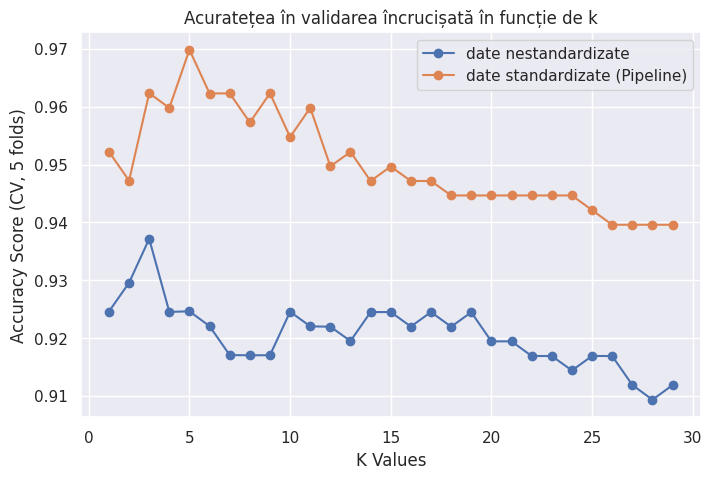

In [29]:
# Comparația curbelor de validare
plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker='o', label='date nestandardizate')
plt.plot(k_values, scores_sc, marker='o', label='date standardizate (Pipeline)')
plt.xlabel('K Values')
plt.ylabel('Accuracy Score (CV, 5 folds)')
plt.title('Acuratețea în validarea încrucișată în funcție de k')
plt.legend()
plt.show()

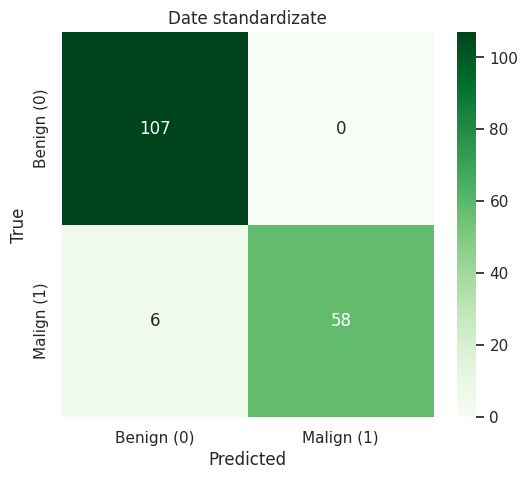

              precision    recall  f1-score   support

           0       0.95      1.00      0.97       107
           1       1.00      0.91      0.95        64

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.97      0.96      0.96       171



In [30]:
# Modelul final pe date standardizate
knn_sc = Pipeline([('scaler', StandardScaler()),
                   ('knn', KNeighborsClassifier(n_neighbors=best_k_sc))])
knn_sc.fit(X_train, y_train)

y_pred_sc = knn_sc.predict(X_test)
y_prob_sc = knn_sc.predict_proba(X_test)[:, 1]

confusion_mat_sc = confusion_matrix(y_test, y_pred_sc)
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_mat_sc, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Benign (0)', 'Malign (1)'], yticklabels=['Benign (0)', 'Malign (1)'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Date standardizate')
plt.show()

print(classification_report(y_test, y_pred_sc))

**Compararea celor două variante pe setul de test**

In [31]:
def evalueaza(y_true, y_hat, y_score):
    return {'k': None,
            'Accuracy':  accuracy_score(y_true, y_hat),
            'Precision': precision_score(y_true, y_hat),
            'Recall':    recall_score(y_true, y_hat),
            'F1':        f1_score(y_true, y_hat),
            'AUC':       roc_auc_score(y_true, y_score)}

rez = pd.DataFrame({'Nestandardizat': evalueaza(y_test, y_pred, y_prob),
                    'Standardizat':   evalueaza(y_test, y_pred_sc, y_prob_sc)}).T
rez['k'] = [best_k, best_k_sc]
rez.round(4)

,k,Accuracy,Precision,Recall,F1,AUC
Nestandardizat,3,0.9298,0.9062,0.9062,0.9062,0.9477
Standardizat,5,0.9649,1.0000,0.9062,0.9508,0.9798


**Interpretare:** după standardizare toate cele 30 de variabile contribuie la calculul distanței. Acuratețea, precizia și AUC cresc vizibil: dispar alarmele false (tumori benigne clasificate drept maligne). Recall-ul pentru tumorile maligne nu crește automat, pentru că k a fost ales după acuratețe; dacă obiectivul este să nu ratăm tumorile maligne, hiperparametrii trebuie aleși după recall (vezi GridSearchCV mai jos).

**Notă:** în cele două variante k ales poate diferi, pentru că structura vecinătăților se schimbă complet după standardizare.

**Opțional: căutarea simultană a mai multor hiperparametri cu GridSearchCV**

Putem căuta în același timp numărul de vecini, tipul ponderării și distanța (p=1 Manhattan, p=2 euclidiană). Folosim `scoring='recall'`, deoarece ne interesează în primul rând să nu ratăm tumorile maligne.

In [32]:
pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid = {'knn__n_neighbors': list(range(1, 30, 2)),
              'knn__weights': ['uniform', 'distance'],
              'knn__p': [1, 2]}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='recall', n_jobs=-1)
grid.fit(X_train, y_train)

print('Cei mai buni hiperparametri:', grid.best_params_)
print('Recall mediu în CV:', round(grid.best_score_, 4))
print(classification_report(y_test, grid.predict(X_test)))

Cei mai buni hiperparametri: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
Recall mediu în CV: 0.946
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       107
           1       1.00      0.94      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171



# KNN - exemplu de clasificare multiclasa

**Despre baza de date**
Imaginați-vă că un furnizor de telecomunicații și-a segmentat baza de clienți în funcție de tiparele de utilizare a serviciilor, clasificând clienții în patru grupuri.
Dacă datele demografice pot fi folosite pentru a prezice apartenența la grup, compania poate personaliza ofertele pentru clienții potențiali individuali.
Este o problemă de clasificare.
Adică, având în vedere setul de date, cu etichete predefinite, trebuie să construim un model care să fie utilizat pentru a prezice clasa unui caz nou sau necunoscut.

In [34]:
df = pd.read_csv('/content/drive/MyDrive/Machine Learning 2026/teleCust1000t.csv')
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,4,5,0.0,0,2,1
1,3,11,33,1,7,136.0,5,5,0.0,0,6,4
2,3,68,52,1,24,116.0,1,29,0.0,1,2,3
3,2,33,33,0,12,33.0,2,0,0.0,1,1,1
4,2,23,30,1,9,30.0,1,2,0.0,0,4,3


**VIZUALIZAREA DATELOR SI ANALIZA EXPLORATORIE**

In [35]:
#Categoriile variabilei target
df['custcat'].value_counts()

,count
custcat,
3,281
1,266
4,236
2,217


array([[<Axes: title={'center': 'income'}>]], dtype=object)

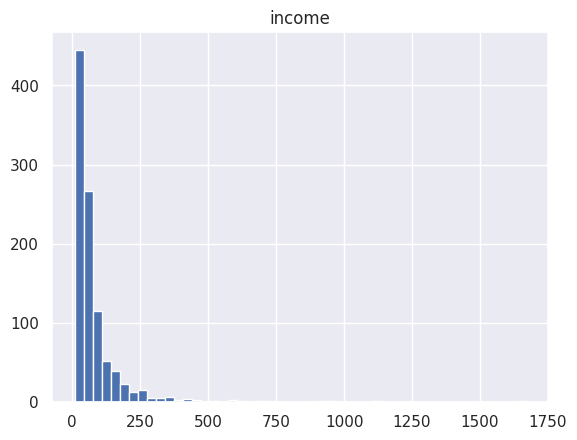

In [36]:
#Histograma variabilei income
df.hist(column='income', bins=50)

Categoriile variabilei target `custcat`, conform descrierii originale a setului de date (IBM):
1 = Basic Service, 2 = E-Service, 3 = Plus Service, 4 = Total Service.

In [37]:
# Definirea matricilor X și y
X = df[['region', 'tenure', 'age', 'marital', 'address', 'income', 'ed', 'employ', 'retire', 'gender', 'reside']].values
y = df['custcat'].values
X[0:5], y[0:5]

(array([[  2.,  13.,  44.,   1.,   9.,  64.,   4.,   5.,   0.,   0.,   2.],
        [  3.,  11.,  33.,   1.,   7., 136.,   5.,   5.,   0.,   0.,   6.],
        [  3.,  68.,  52.,   1.,  24., 116.,   1.,  29.,   0.,   1.,   2.],
        [  2.,  33.,  33.,   0.,  12.,  33.,   2.,   0.,   0.,   1.,   1.],
        [  2.,  23.,  30.,   1.,   9.,  30.,   1.,   2.,   0.,   0.,   4.]]),
 array([1, 4, 3, 1, 3]))

In [38]:
# Împărțirea în date de antrenare și de test ÎNAINTE de standardizare
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4, stratify=y)
print('Train:', X_train.shape, '  Test:', X_test.shape)

Train: (800, 11)   Test: (200, 11)


**Standardizarea datelor** oferă media zero a datelor și varianța egală cu 1. Este recomandată în cazul algoritmilor precum KNN, care se bazează pe distanța dintre puncte. Aici variabila `income` ia valori până la 1668, iar `marital` sau `gender` doar 0 sau 1.

Ca și în primul exemplu, comparăm cele două variante, iar standardizarea se face în interiorul fiecărui fold, printr-un `Pipeline`.

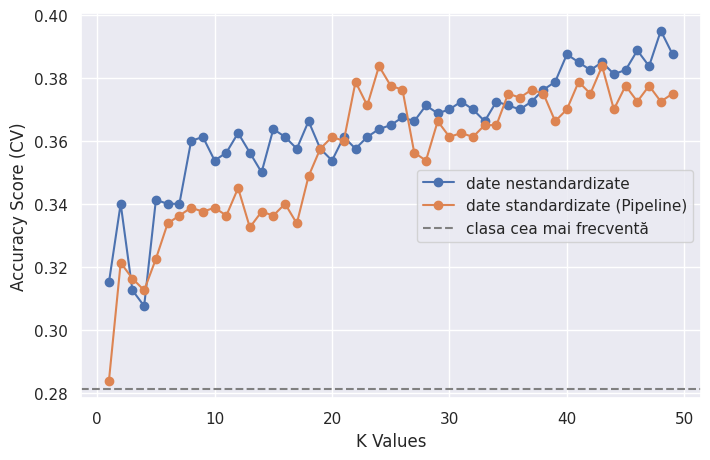

Nestandardizat: k = 48  acuratețe CV = 0.395
Standardizat:   k = 43  acuratețe CV = 0.3838


In [39]:
cv_mc = StratifiedKFold(n_splits=5, shuffle=True, random_state=4)
k_values = list(range(1, 50))
scores_raw, scores_std = [], []

for k in k_values:
    scores_raw.append(cross_val_score(KNeighborsClassifier(n_neighbors=k),
                                      X_train, y_train, cv=cv_mc).mean())
    scores_std.append(cross_val_score(Pipeline([('scaler', StandardScaler()),
                                                ('knn', KNeighborsClassifier(n_neighbors=k))]),
                                      X_train, y_train, cv=cv_mc).mean())

plt.figure(figsize=(8, 5))
plt.plot(k_values, scores_raw, marker='o', label='date nestandardizate')
plt.plot(k_values, scores_std, marker='o', label='date standardizate (Pipeline)')
plt.axhline(pd.Series(y_train).value_counts(normalize=True).max(), color='grey', linestyle='--',
            label='clasa cea mai frecventă')
plt.xlabel('K Values')
plt.ylabel('Accuracy Score (CV)')
plt.legend()
plt.show()

best_k_raw = k_values[int(np.argmax(scores_raw))]
best_k = k_values[int(np.argmax(scores_std))]
print('Nestandardizat: k =', best_k_raw, ' acuratețe CV =', round(max(scores_raw), 4))
print('Standardizat:   k =', best_k, ' acuratețe CV =', round(max(scores_std), 4))

**Algoritmul KNN cu cel mai bun k, pe date standardizate**

In [40]:
KNN = Pipeline([('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=best_k))]).fit(X_train, y_train)
KNN

Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=43))])

In [41]:
# Predicție
y_pred = KNN.predict(X_test)
y_pred[0:5]

array([1, 2, 4, 3, 3])

In [42]:
print("Train set Accuracy: ", round(metrics.accuracy_score(y_train, KNN.predict(X_train)), 4))
print("Test set Accuracy:  ", round(metrics.accuracy_score(y_test, y_pred), 4))

# Pentru comparație: varianta nestandardizată
KNN_raw = KNeighborsClassifier(n_neighbors=best_k_raw).fit(X_train, y_train)
print("Test set Accuracy (nestandardizat):", round(metrics.accuracy_score(y_test, KNN_raw.predict(X_test)), 4))

Train set Accuracy:  0.4275
Test set Accuracy:   0.41
Test set Accuracy (nestandardizat): 0.335


**Interpretare:** cu 4 clase relativ echilibrate, un model care ghicește la întâmplare are o acuratețe de aproximativ 25%, iar unul care prezice mereu clasa cea mai frecventă are ~28%. KNN depășește aceste repere, dar acuratețea rămâne modestă: variabilele demografice explică doar parțial categoria de client. Comparați și acuratețea pe train cu cea pe test: o diferență mare indică overfitting (k prea mic).

**Confusion matrix**

In [43]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.grid(False)
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Confusion matrix, without normalization
[[32  4 14  3]
 [15  8 13  8]
 [21  4 24  7]
 [11  7 11 18]]


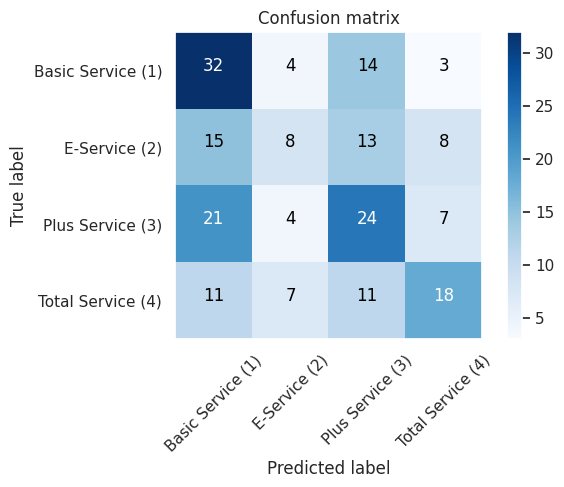

              precision    recall  f1-score   support

           1       0.41      0.60      0.48        53
           2       0.35      0.18      0.24        44
           3       0.39      0.43      0.41        56
           4       0.50      0.38      0.43        47

    accuracy                           0.41       200
   macro avg       0.41      0.40      0.39       200
weighted avg       0.41      0.41      0.40       200



In [44]:
# Reprezentarea confusion matrix
# Ordinea etichetelor urmează ordinea claselor 1, 2, 3, 4
confusion_mat = confusion_matrix(y_test, y_pred, labels=[1, 2, 3, 4])

plt.figure()
plot_confusion_matrix(confusion_mat,
                      classes=['Basic Service (1)', 'E-Service (2)', 'Plus Service (3)', 'Total Service (4)'],
                      normalize=False, title='Confusion matrix')
plt.show()

print(classification_report(y_test, y_pred))

# Exerciții

1. Repetați analiza pe setul Breast Cancer folosind distanța Manhattan (`p=1`). Se schimbă k optim?
2. Înlocuiți `StandardScaler` cu `MinMaxScaler` în Pipeline. Comparați rezultatele.
3. Variabila `region` din setul teleCust este nominală (1, 2, 3 sunt doar coduri). Codificați-o one-hot (de exemplu cu `pd.get_dummies` sau `OneHotEncoder` într-un `ColumnTransformer`) și refaceți modelul.
4. Pentru setul Breast Cancer, alegeți un prag de decizie mai mic decât 0,5 pe `predict_proba` astfel încât recall-ul pentru clasa malignă pe datele de antrenare (în validare încrucișată) să fie cel puțin 0,98.